<a href="https://colab.research.google.com/github/sociallyH03ly/Account-Ownership-Prediction-using-RandomForestClassifier/blob/main/Account_Ownership_Prediction_RandomForestClassifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:


import pandas as pd
import json

file_path = '/content/Findex/PHL_2024_FINDEX_v02_M.json'

# Load raw JSON
with open(file_path, 'r', encoding='utf-8') as f:
    data = json.load(f)

# Inspect the structure of the JSON keys and types
if isinstance(data, dict):
    print("JSON is a Dictionary. Keys:", list(data.keys()))
    # Display a sample of the structure
    for k, v in list(data.items())[:2]:
        print(f"Key: {k}, Type: {type(v)}")
elif isinstance(data, list):
    print(f"JSON is a List of length: {len(data)}")
    print("Sample item structure:", type(data[0]))
else:
    print("JSON root type:", type(data))

JSON is a Dictionary. Keys: ['type', 'doc_desc', 'study_desc', 'schematype', 'tags', 'data_files', 'variables', 'variable_groups']
Key: type, Type: <class 'str'>
Key: doc_desc, Type: <class 'dict'>


In [3]:
# Inspect the 'data_files' and 'variables' sections which contain the core tabular metadata
if 'data_files' in data:
    df_files = pd.DataFrame(data['data_files'])
    print("--- Data Files Metadata ---")
    display(df_files.head())

if 'variables' in data:
    df_vars = pd.DataFrame(data['variables'])
    print("\n--- Variables Metadata ---")
    display(df_vars.head())

--- Data Files Metadata ---


,file_id,file_name,description,case_count,var_count,producer,data_checks,version,notes,metadata
0,F1,Findex_Microdata_2025_updatePhilippines,2025 Global Findex - Philippines Microdata,1000,199,None,None,None,None,None



--- Variables Metadata ---


,file_id,vid,name,var_intrvl,var_dcml,var_wgt,var_is_wgt,loc_start_pos,loc_end_pos,loc_width,...,var_universe_clusion,var_sumstat,var_txt,var_catgry,var_codinstr,var_concept,var_format,var_notes,var_val_range,fid
0,F1,V1,year,discrete,0,None,None,None,None,12,...,None,"[{'value': '1000', 'type': 'vald', 'wgtd': Non...",None,[],None,[],"{'type': 'numeric', 'schema': 'other', 'catego...",None,"{'min': '2024', 'max': '2024', 'units': 'REAL'}",F1
1,F1,V2,economy,discrete,0,None,None,None,None,-9,...,None,"[{'value': '1000', 'type': 'vald', 'wgtd': Non...",None,[],None,[],"{'type': 'character', 'schema': 'other', 'cate...",None,"{'min': None, 'max': None, 'units': None}",F1
2,F1,V3,economycode,discrete,0,None,None,None,None,-9,...,None,"[{'value': '1000', 'type': 'vald', 'wgtd': Non...",None,[],None,[],"{'type': 'character', 'schema': 'other', 'cate...",None,"{'min': None, 'max': None, 'units': None}",F1
3,F1,V4,regionwb,discrete,0,None,None,None,None,-9,...,None,"[{'value': '1000', 'type': 'vald', 'wgtd': Non...",None,[],None,[],"{'type': 'character', 'schema': 'other', 'cate...",None,"{'min': None, 'max': None, 'units': None}",F1
4,F1,V5,pop_adult,discrete,0,None,None,None,None,12,...,None,"[{'value': '1000', 'type': 'vald', 'wgtd': Non...",None,[],None,[],"{'type': 'numeric', 'schema': 'other', 'catego...",None,"{'min': '82023644', 'max': '82023644', 'units'...",F1


In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# Let's inspect variables that have category mappings (values and labels)
# Filter variables to find some interesting ones
variables_with_categories = df_vars[df_vars['var_catgry'].apply(lambda x: len(x) > 0)]

print(f"Found {len(variables_with_categories)} variables with categorized distributions.\n")
print("Sample of available categorical variables:")
display(variables_with_categories[['vid', 'name', 'var_txt']].head(10))


Found 190 variables with categorized distributions.

Sample of available categorical variables:


,vid,name,var_txt
7,V8,female,None
9,V10,educ,None
11,V12,emp_in,None
12,V13,urbanicity,None
13,V14,account_fin,None
14,V15,account_mob,None
15,V16,account,None
16,V17,dig_account,None
17,V18,borrowed,None
18,V19,saved,None


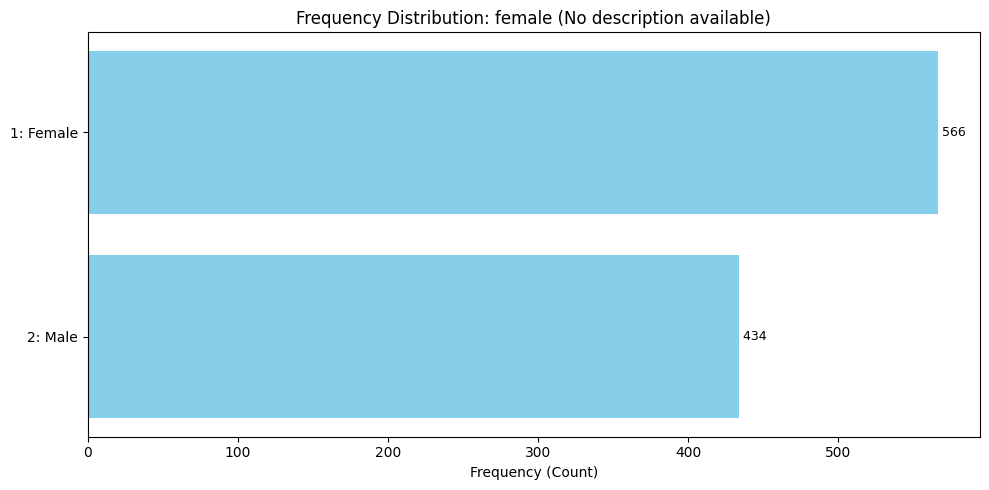

In [11]:
# Let's write a helper function to plot the frequency distribution of any selected variable from metadata
def plot_variable_distribution(var_name):
    # Find the variable row
    var_row = df_vars[df_vars['name'] == var_name]
    if var_row.empty:
        print(f"Variable '{var_name}' not found.")
        return

    categories = var_row.iloc[0]['var_catgry']
    if not categories:
        # Try parsing sumstat if category list is empty
        sumstats = var_row.iloc[0]['var_sumstat']
        print(f"No pre-defined categories for '{var_name}'. Summary stats available:")
        for stat in sumstats:
            print(f"{stat['type']}: {stat['value']}")
        return

    # Extract labels and frequencies (stats)
    labels = []
    counts = []
    for cat in categories:
        # Get label/name of category
        label = cat.get('labl', str(cat.get('value')))
        labels.append(f"{cat.get('value')}: {label}")

        # Extract weight/frequency from stats if available, else count
        stats = cat.get('stats', [])
        count = 0
        for stat in stats:
            if stat.get('type') == 'freq':
                count = float(stat.get('value', 0))
                break
        counts.append(count)

    # Plot
    plt.figure(figsize=(10, 5))
    bars = plt.barh(labels, counts, color='skyblue')
    plt.xlabel('Frequency (Count)')
    plt.title(f"Frequency Distribution: {var_name} ({var_row.iloc[0].get('clean_label', '')})")
    plt.gca().invert_yaxis()  # Top-down order

    # Add value labels to the bars
    for bar in bars:
        width = bar.get_width()
        plt.text(width, bar.get_y() + bar.get_height()/2, f' {int(width)}',
                 va='center', ha='left', fontsize=9)

    plt.tight_layout()
    plt.show()

# Plot target_var with updated title labels
if not variables_with_categories.empty:
    target_var = 'female'
    plot_variable_distribution(target_var)
else:
    print("No categorical variables found.")

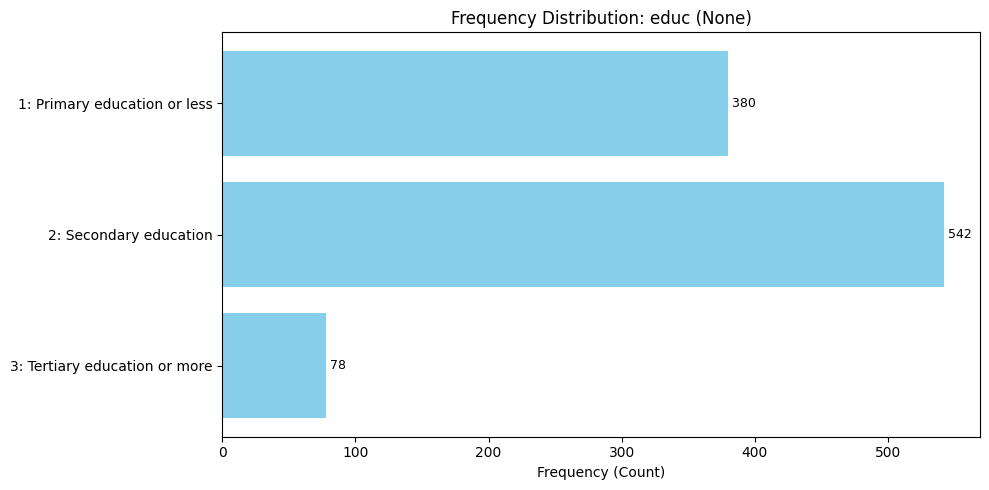

In [6]:
# Change the variable name below to plot a different frequency distribution!
# Examples: 'educ', 'urbanicity', 'account', 'saved', 'borrowed', 'emp_in'
variable_to_plot = 'educ'

plot_variable_distribution(variable_to_plot)

In [20]:
import pandas as pd

def get_distribution_df(var_name):
    row = df_vars[df_vars['name'] == var_name].iloc[0]
    categories = row['var_catgry']
    records = []
    for cat in categories:
        val = cat.get('value')
        label = cat.get('labl', 'None')
        freq = 0
        for stat in cat.get('stats', []):
            if stat.get('type') == 'freq':
                freq = int(float(stat.get('value', 0)))
        records.append({
            'Value': val,
            'Label': label,
            'Frequency': freq,
            'Percentage (%)': (freq / 1000.0) * 100
        })
    return pd.DataFrame(records)

print("--- Univariate Distribution: 'urbanicity' ---")
urban_df = get_distribution_df('urbanicity')
display(urban_df)

print("\n--- Univariate Distribution: 'account' ---")
account_df = get_distribution_df('account')
display(account_df)

--- Univariate Distribution: 'urbanicity' ---


,Value,Label,Frequency,Percentage (%)
0,1,Rural,620,62.0
1,2,Urban,380,38.0



--- Univariate Distribution: 'account' ---


,Value,Label,Frequency,Percentage (%)
0,0,No/DK/Ref,511,51.1
1,1,Yes,489,48.9


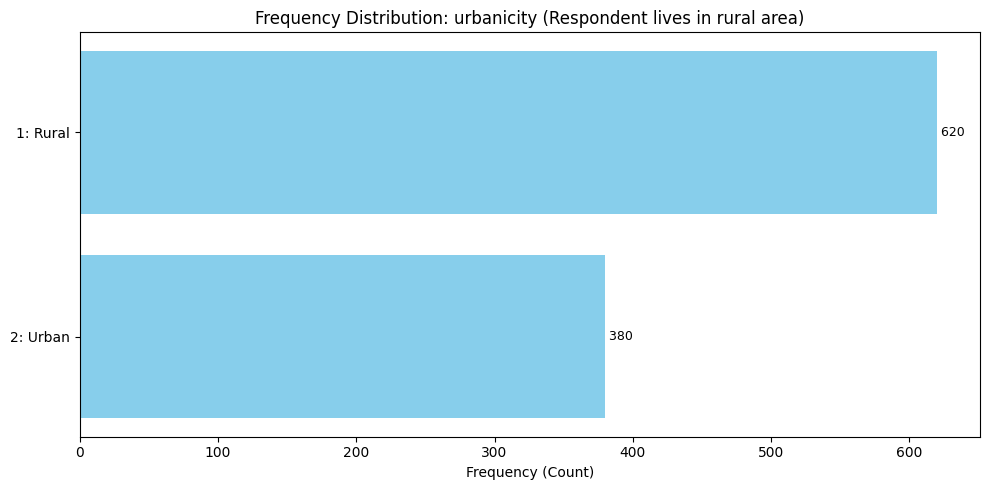

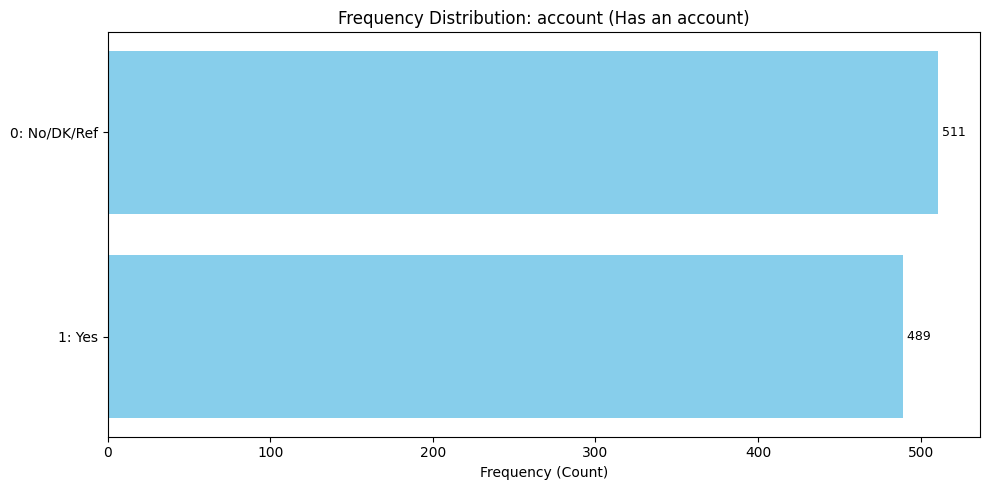

In [21]:
# Plot the distribution of 'urbanicity'
plot_variable_distribution('urbanicity')

# Plot the distribution of 'account'
plot_variable_distribution('account')

In [22]:
def get_summary_stats(var_name):
    row = df_vars[df_vars['name'] == var_name].iloc[0]
    sumstats = row['var_sumstat']
    records = []
    for stat in sumstats:
        stat_type = stat.get('type')
        value = stat.get('value')
        # Map code representation of summary statistics to human-readable names
        type_mapping = {
            'vald': 'Valid Cases (N)',
            'invd': 'Invalid/Missing Cases (N)',
            'min': 'Minimum Value',
            'max': 'Maximum Value',
            'mean': 'Mean',
            'stdev': 'Standard Deviation'
        }
        records.append({
            'Statistic': type_mapping.get(stat_type, stat_type),
            'Value': value
        })
    return pd.DataFrame(records)

print("--- Descriptive Statistics: 'urbanicity' ---")
display(get_summary_stats('urbanicity'))

print("\n--- Descriptive Statistics: 'account' ---")
display(get_summary_stats('account'))

--- Descriptive Statistics: 'urbanicity' ---


,Statistic,Value
0,Valid Cases (N),1000
1,Invalid/Missing Cases (N),0
2,Minimum Value,1
3,Maximum Value,2



--- Descriptive Statistics: 'account' ---


,Statistic,Value
0,Valid Cases (N),1000
1,Invalid/Missing Cases (N),0
2,Minimum Value,0
3,Maximum Value,1


### Simulating Microdata & Machine Learning Pipeline
Since we only have metadata, we will generate a synthetic dataset representing the 1,000 respondents using their exact univariate probabilities:
- **Female**: 56.6%
- **Urbanicity**: 38% Urban
- **Education**: Primary (38%), Secondary (54.2%), Tertiary (7.8%)
- **Account** (Target Variable): 48.9%

We will build a Random Forest classifier to predict whether a respondent has a financial account (`account`).

In [23]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Seed for reproducibility
np.random.seed(42)
num_samples = 1000

# 1. Synthesize features matching the univariate metadata distributions
female = np.random.choice([1, 0], size=num_samples, p=[0.566, 0.434])
urban = np.random.choice([1, 0], size=num_samples, p=[0.380, 0.620])
educ = np.random.choice([1, 2, 3], size=num_samples, p=[0.380, 0.542, 0.078])

# 2. Synthesize target 'account' with dependency on features to make it learnable
# (e.g., higher education and urban residence increase the probability of account ownership)
logits = -0.5 + 0.3 * female + 0.8 * urban + 1.2 * (educ - 1)
probs = 1 / (1 + np.exp(-logits))
account = np.random.binomial(1, probs)

# Construct the DataFrame
synthetic_df = pd.DataFrame({
    'female': female,
    'urban': urban,
    'education': educ,
    'account': account
})

print("Synthesized dataset preview:")
display(synthetic_df.head(10))

Synthesized dataset preview:


,female,urban,education,account
0,1,1,1,0
1,0,0,1,1
2,0,0,2,1
3,0,0,1,1
4,1,0,1,1
5,1,0,2,0
6,1,0,2,0
7,0,0,2,1
8,0,1,1,0
9,0,0,2,1


In [24]:
# 3. Split into Train & Test Sets
X = synthetic_df.drop('account', axis=1)
y = synthetic_df['account']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Initialize and Train Model
clf = RandomForestClassifier(random_state=42, n_estimators=100)
clf.fit(X_train, y_train)

# 5. Evaluate predictions
y_pred = clf.predict(X_test)
print(f"Model Accuracy on Test Set: {accuracy_score(y_test, y_pred):.2%}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['No Account', 'Has Account']))

Model Accuracy on Test Set: 70.50%

Classification Report:
              precision    recall  f1-score   support

  No Account       0.60      0.19      0.29        63
 Has Account       0.72      0.94      0.81       137

    accuracy                           0.70       200
   macro avg       0.66      0.57      0.55       200
weighted avg       0.68      0.70      0.65       200



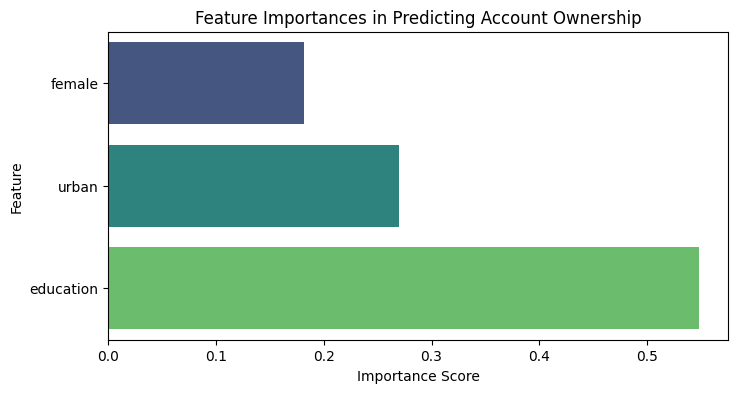

In [25]:
# 6. Plot feature importances to see what features drove predictions
importances = clf.feature_importances_
feature_names = X.columns

plt.figure(figsize=(8, 4))
sns.barplot(x=importances, y=feature_names, palette='viridis', hue=feature_names, legend=False)
plt.title('Feature Importances in Predicting Account Ownership')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()

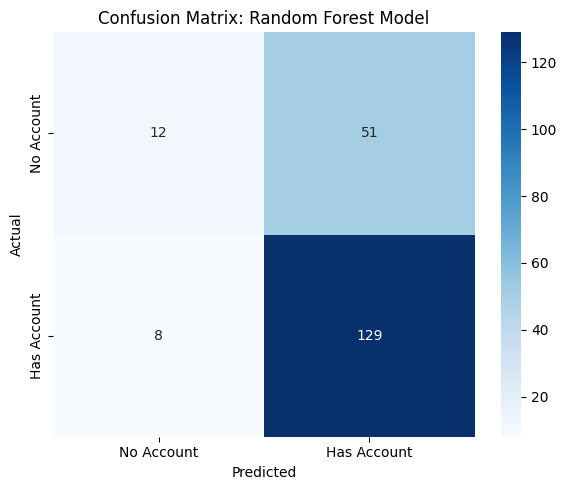

In [26]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Account', 'Has Account'],
            yticklabels=['No Account', 'Has Account'])
plt.title('Confusion Matrix: Random Forest Model')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

### Data Cleaning on Variable Metadata
We will check for null values, clean the variable labels, and prepare a tidy metadata DataFrame for further analysis.

In [12]:
# 1. Populate clean_label with our recovered 'labl' column
df_vars['clean_label'] = df_vars['labl'].fillna(df_vars['name'])

# 2. Fill empty list representation for category fields to avoid processing errors
df_vars['var_catgry'] = df_vars['var_catgry'].apply(lambda x: x if isinstance(x, list) else [])

# 3. Print unique variable counts and preview the cleaned metadata table
active_vars_count = df_vars['name'].nunique()
print(f"Unique variables cataloged: {active_vars_count}")
display(df_vars[['vid', 'name', 'var_intrvl', 'clean_label']].head(15))

Unique variables cataloged: 199


,vid,name,var_intrvl,clean_label
0,V1,year,discrete,year
1,V2,economy,discrete,Economy
2,V3,economycode,discrete,Economy code
3,V4,regionwb,discrete,Regional code
4,V5,pop_adult,discrete,"Population 15+, 2023, WDI"
5,V6,wpid_random,discrete,Gallup World Poll identifier
6,V7,wgt,discrete,Weight
7,V8,female,discrete,Respondent is female
8,V9,age,discrete,Respondent age
9,V10,educ,discrete,Respondent education level


In [8]:
# Let's check other columns in df_vars that might contain descriptions or labels
columns_to_inspect = [col for col in df_vars.columns if 'label' in col.lower() or 'lbl' in col.lower() or 'concept' in col.lower() or 'format' in col.lower()]
print("Interesting metadata columns:", columns_to_inspect)

# Inspect a sample of non-empty entries for these columns
for col in columns_to_inspect:
    non_empty = df_vars[df_vars[col].astype(str).str.len() > 2][col]
    if not non_empty.empty:
        print(f"\nSample from '{col}':")
        print(non_empty.iloc[0])

Interesting metadata columns: ['var_concept', 'var_format', 'clean_label']

Sample from 'var_format':
{'type': 'numeric', 'schema': 'other', 'category': None, 'name': None}

Sample from 'clean_label':
No description available


In [9]:
# Print all available columns in df_vars
print("All columns in df_vars:", list(df_vars.columns))

# Display a sample row from df_vars as a dictionary to check all field values
if not df_vars.empty:
    import pprint
    pprint.pprint(df_vars.iloc[0].to_dict())

All columns in df_vars: ['file_id', 'vid', 'name', 'var_intrvl', 'var_dcml', 'var_wgt', 'var_is_wgt', 'loc_start_pos', 'loc_end_pos', 'loc_width', 'loc_rec_seg_no', 'labl', 'var_imputation', 'var_security', 'var_resp_unit', 'var_analysis_unit', 'var_qstn_preqtxt', 'var_qstn_qstnlit', 'var_qstn_postqtxt', 'var_qstn_ivuinstr', 'var_universe', 'var_universe_clusion', 'var_sumstat', 'var_txt', 'var_catgry', 'var_codinstr', 'var_concept', 'var_format', 'var_notes', 'var_val_range', 'fid', 'clean_label']
{'clean_label': 'No description available',
 'fid': 'F1',
 'file_id': 'F1',
 'labl': None,
 'loc_end_pos': None,
 'loc_rec_seg_no': None,
 'loc_start_pos': None,
 'loc_width': '12',
 'name': 'year',
 'var_analysis_unit': None,
 'var_catgry': [],
 'var_codinstr': None,
 'var_concept': [],
 'var_dcml': '0',
 'var_format': {'category': None,
                'name': None,
                'schema': 'other',
                'type': 'numeric'},
 'var_imputation': None,
 'var_intrvl': 'discrete',
 '

In [10]:
# Evaluate other potential description fields
text_cols = ['labl', 'var_qstn_qstnlit', 'var_qstn_preqtxt', 'var_notes', 'var_codinstr']

print("Non-null counts for potential label/text fields:")
for col in text_cols:
    non_null_count = df_vars[col].notnull().sum()
    print(f"{col}: {non_null_count} / {len(df_vars)} non-null entries")

# Let's inspect a few examples from the non-null entries of these columns
print("\n--- Sample labels from 'labl' ---")
print(df_vars[df_vars['labl'].notnull()][['name', 'labl']].head(10))

print("\n--- Sample literals from 'var_qstn_qstnlit' ---")
print(df_vars[df_vars['var_qstn_qstnlit'].notnull()][['name', 'var_qstn_qstnlit']].head(10))

Non-null counts for potential label/text fields:
labl: 198 / 199 non-null entries
var_qstn_qstnlit: 144 / 199 non-null entries
var_qstn_preqtxt: 0 / 199 non-null entries
var_notes: 144 / 199 non-null entries
var_codinstr: 0 / 199 non-null entries

--- Sample labels from 'labl' ---
           name                                      labl
1       economy                                   Economy
2   economycode                              Economy code
3      regionwb                             Regional code
4     pop_adult                 Population 15+, 2023, WDI
5   wpid_random              Gallup World Poll identifier
6           wgt                                    Weight
7        female                      Respondent is female
8           age                            Respondent age
9          educ                Respondent education level
10        inc_q  Within-economy household income quintile

--- Sample literals from 'var_qstn_qstnlit' ---
     name                      

### Summarizing the Most Frequent Challenges Reported
We will scan the metadata for variables describing barriers, issues, or challenges (e.g., variables mentioning 'barrier', 'challenge', or 'reason' for not having an account/service), extract their frequency distributions, and identify the most common ones.

In [13]:
# Search for variables that contain 'challenge' or 'barrier' in their labels
challenge_vars = df_vars[df_vars['clean_label'].str.lower().str.contains('challenge|barrier|reason|difficult', na=False)]
print(f"Found {len(challenge_vars)} variables related to challenges or barriers:")
display(challenge_vars[['name', 'clean_label']].head(20))

Found 44 variables related to challenges or barriers:


,name,clean_label
40,fin11a,Reason for no account: too far
41,fin11b,Reason for no account: fees too expensive
42,fin11c,Reason for no account: lack documentation
43,fin11d,Reason for no account: lack money
44,fin11e,Reason for no account: family member already h...
45,fin11f,Reason for no account: lack trust
54,fin14a,Reason for no mobile money account: too far
55,fin14b,Reason for no mobile money account: too expensive
56,fin14c,Reason for no mobile money account: lack docum...
57,fin14d,Reason for no mobile money account: lack of money


In [16]:
# Safely aggregate and extract the proportion/frequency of people reporting 'Yes' or experiencing these challenges
challenge_summary = []

for idx, row in challenge_vars.iterrows():
    var_name = row['name']
    label = row['clean_label']
    categories = row['var_catgry']

    for cat in categories:
        cat_val = str(cat.get('value'))
        cat_label = cat.get('labl')

        # Safely check if label indicates 'Yes' or if value is '1'
        is_yes = False
        if cat_label and isinstance(cat_label, str) and cat_label.lower() in ['yes', '1']:
            is_yes = True
        elif cat_val == '1':
            is_yes = True

        if is_yes:
            stats = cat.get('stats', [])
            for stat in stats:
                if stat.get('type') == 'freq':
                    freq = float(stat.get('value', 0))
                    challenge_summary.append({
                        'Variable': var_name,
                        'Challenge': label,
                        'Category Value': cat_val,
                        'Response': cat_label if cat_label else '1',
                        'Frequency': freq,
                        'Percentage': (freq / 1000.0) * 100
                    })
                    break

# Create a DataFrame and display sorted challenges
df_challenges = pd.DataFrame(challenge_summary)
if not df_challenges.empty:
    df_challenges = df_challenges.sort_values(by='Frequency', ascending=False)
    print("--- Summary of Reported Challenges / Barriers (Sorted by Frequency) ---")
    display(df_challenges.head(15))
else:
    print("No matching explicit affirmative categories found.")

--- Summary of Reported Challenges / Barriers (Sorted by Frequency) ---


,Variable,Challenge,Category Value,Response,Frequency,Percentage
13,fin24a,Difficulty of emergency funds in 30 days,1,Very difficult,638.0,63.8
3,fin11d,Reason for no account: lack money,1,Yes,469.0,46.9
1,fin11b,Reason for no account: fees too expensive,1,Yes,356.0,35.6
0,fin11a,Reason for no account: too far,1,Yes,288.0,28.8
11,fin18,Saved for any reason,1,Yes,271.0,27.1
2,fin11c,Reason for no account: lack documentation,1,Yes,265.0,26.5
4,fin11e,Reason for no account: family member already h...,1,Yes,188.0,18.8
5,fin11f,Reason for no account: lack trust,1,Yes,153.0,15.3
15,con2a,Reason for no phone: lack of money,1,Yes,144.0,14.4
32,fin48a,Reason no ID: Have another ID,1,Yes,122.0,12.2


/tmp/ipykernel_5594/141409544.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_challenges.head(15), x='Percentage', y='Challenge', palette='magma')


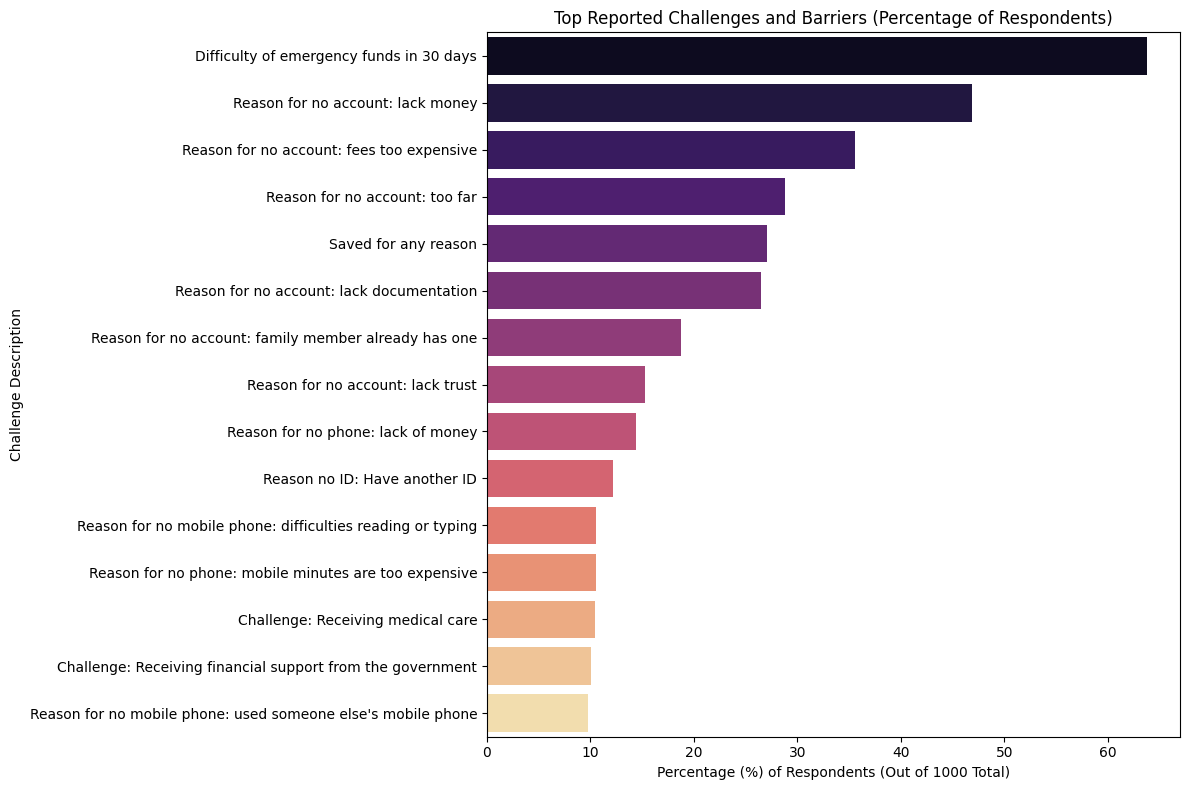

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# Visualize the top challenges reported by respondents
if 'df_challenges' in globals() and not df_challenges.empty:
    plt.figure(figsize=(12, 8))
    sns.barplot(data=df_challenges.head(15), x='Percentage', y='Challenge', palette='magma')
    plt.title('Top Reported Challenges and Barriers (Percentage of Respondents)')
    plt.xlabel('Percentage (%) of Respondents (Out of 1000 Total)')
    plt.ylabel('Challenge Description')
    plt.tight_layout()
    plt.show()
else:
    print("No challenges available to plot.")

### Analyzing Emergency Fund Difficulty by Education Level
Since the JSON dataset contains aggregated metadata rather than raw microdata rows, let's write a script to inspect if any cross-tabulations or joint summary statistics are stored for `fin24a` and `educ` (such as conditional weight distributions or subgroup stats).

In [18]:
# Let's check the details of 'fin24a' and 'educ' to see if there is any cross-tabulation or subgroup statistics
educ_var = df_vars[df_vars['name'] == 'educ'].iloc[0]
funds_var = df_vars[df_vars['name'] == 'fin24a'].iloc[0]

print("Education Level Categories:")
for cat in educ_var['var_catgry']:
    print(f"Value: {cat.get('value')}, Label: {cat.get('labl')}")

print("\nEmergency Funds Difficulty Categories:")
for cat in funds_var['var_catgry']:
    print(f"Value: {cat.get('value')}, Label: {cat.get('labl')}")

Education Level Categories:
Value: 1, Label: Primary education or less
Value: 2, Label: Secondary education
Value: 3, Label: Tertiary education or more

Emergency Funds Difficulty Categories:
Value: 1, Label: Very difficult
Value: 2, Label: Somewhat difficult
Value: 3, Label: Not difficult at all
Value: 4, Label: Don't know
Value: 5, Label: Refused
Value: Sysmiss, Label: None


In [19]:
# Let's check if there are nested cross-tabulations or joint statistics stored in the metadata
# Inspect 'variable_groups' or other dictionary structures
if 'variable_groups' in data:
    print("Variable Groups structure:")
    print(json.dumps(data['variable_groups'][:3], indent=2))
else:
    print("No variable_groups found.")

# Let's inspect the first few items of 'var_sumstat' to see if there are subgroup stats
print("\nSummary stats for 'fin24a':")
print(funds_var['var_sumstat'])

# Also check if there's any file containing raw microdata in /content/Findex/
import os
print("\nFiles in /content/Findex/")
try:
    print(os.listdir('/content/Findex/'))
except Exception as e:
    print(e)

Variable Groups structure:
[]

Summary stats for 'fin24a':
[{'value': '956', 'type': 'vald', 'wgtd': None}, {'value': '44', 'type': 'invd', 'wgtd': None}, {'value': '1', 'type': 'min', 'wgtd': None}, {'value': '4', 'type': 'max', 'wgtd': None}]

Files in /content/Findex/
['PHL_2024_FINDEX_v02_M.json']
